# Machine Failure Prediction with XGBoost (AI4I 2020) + MLflow + Grid Search

Brief analogy: this model is like a technician trained to read four sensors (temperature, rotational speed, torque, and tool wear) and then decide, "Is this machine going to fail or stay safe?" We also give it three "helper calculators" (temperature difference, power, and tool wear x torque) so it does not have to infer those formulas on its own.

Workflow: load data (ClickHouse), perform feature engineering, split into train/validation/test sets, **search hyperparameters with GridSearchCV**, train the baseline and SMOTE models, tune the threshold, evaluate, **log to MLflow (tracking + model registry)**, and run inference on one new data point from the registry.

All configuration is read from environment variables (see the configuration cell), so the same notebook can be run manually or through `papermill` in a CI/CD pipeline.

In [ ]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mlflow
import mlflow.xgboost
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

import time
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score,
                             precision_recall_curve, roc_curve,
                             ConfusionMatrixDisplay)
from xgboost import XGBClassifier

RANDOM_STATE = 42

# ---------------- Configuration (overridable via environment variables) ----------------
DATA_SOURCE = os.getenv("DATA_SOURCE", "clickhouse")        # "clickhouse" | "csv"
DATA_PATH   = os.getenv("DATA_PATH", "../data/ai4i2020.csv") # used when DATA_SOURCE=csv

CH_HOST     = os.getenv("CH_HOST", "localhost")
CH_PORT     = int(os.getenv("CH_PORT", "8123"))             # HTTP port
CH_USER     = os.getenv("CH_USER", "airflow_etl")
CH_PASSWORD = os.getenv("CH_PASSWORD", "airflow_etl")
CH_DATABASE = os.getenv("CH_DATABASE", "erp_ai4i")
CH_TABLE    = os.getenv("CH_TABLE", "machine_operation")

MLFLOW_TRACKING_URI   = os.getenv("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000")
MLFLOW_EXPERIMENT     = os.getenv("MLFLOW_EXPERIMENT", "machine-failure-prediction")
REGISTERED_MODEL_NAME = os.getenv("MLFLOW_MODEL_NAME", "machine_failure_xgb")
MODEL_ALIAS           = os.getenv("MLFLOW_MODEL_ALIAS", "champion")
MODEL_TO_REGISTER     = os.getenv("MODEL_TO_REGISTER", "auto")  # auto | baseline | smote
GIT_SHA               = os.getenv("GIT_SHA", "local")
GRID_CV_FOLDS         = int(os.getenv("GRID_CV_FOLDS", "3"))

## 1. Load data

Primary source: the ClickHouse table populated by the Airflow DAG (Postgre -> ClickHouse). For local experiments, set `DATA_SOURCE=csv`.

In [183]:
COLUMNS = ["udi", "product_id", "type", "air_temp_k", "process_temp_k",
           "rpm", "torque_nm", "tool_wear_min", "machine_failure",
           "twf", "hdf", "pwf", "osf", "rnf"]
INT_COLS   = ["udi", "rpm", "tool_wear_min", "machine_failure", "twf", "hdf", "pwf", "osf", "rnf"]
FLOAT_COLS = ["air_temp_k", "process_temp_k", "torque_nm"]


def load_from_clickhouse() -> pd.DataFrame:
    print("Data retrieved from Clickhouse")
    import clickhouse_connect
    client = clickhouse_connect.get_client(
        host=CH_HOST, port=CH_PORT, username=CH_USER,
        password=CH_PASSWORD, database=CH_DATABASE)
    return client.query_df(f"SELECT {', '.join(COLUMNS)} FROM {CH_TABLE} ORDER BY udi")


def load_from_csv() -> pd.DataFrame:
    print("Data retrieved from CSV")
    # The CSV file starts with a BOM, so use utf-8-sig to preserve the first column name
    d = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
    d.columns = COLUMNS
    return d


df = load_from_clickhouse() if DATA_SOURCE == "clickhouse" else load_from_csv()
df = df.astype({**{c: "int64" for c in INT_COLS}, **{c: "float64" for c in FLOAT_COLS}})

print("Data source:", DATA_SOURCE)
print(df.shape)
df.head()

Data retrieved from CSV
Data source: csv
(10000, 14)


,udi,product_id,type,air_temp_k,process_temp_k,rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
0,3772,M18631,M,302.3,311.0,1384,49.7,192,0,0,0,0,0,0
1,6673,L53852,L,301.6,310.7,1424,50.5,214,0,0,0,0,0,0
2,7262,L54441,L,300.4,310.5,1818,25.1,14,0,0,0,0,0,0
3,761,L47940,L,296.7,307.8,1505,39.4,236,0,0,0,0,0,0
4,3780,L50959,L,302.3,311.0,1657,31.1,3,0,0,0,0,0,0


In [184]:
print(df.isna().sum().sum(), "missing values")
print(df["machine_failure"].value_counts())
print(f"Failure rate: {df['machine_failure'].mean():.2%}")

0 missing values
machine_failure
0    9661
1     339
Name: count, dtype: int64
Failure rate: 3.39%


## 2. Feature engineering

The `twf`, `hdf`, `pwf`, `osf`, and `rnf` columns are **dropped** because they leak the label (failure = 1 if any of them is 1). `udi` and `product_id` are identifiers only.

Derived features mirror the physical rules described in the dataset:
- `temp_diff_k`: process temperature minus air temperature (HDF rule)
- `power_w`: torque x rpm x 2pi/60 (PWF rule)
- `wear_torque`: tool wear x torque (OSF rule)

In [185]:
TYPE_MAP = {"L": 0, "M": 1, "H": 2}

def make_features(d: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=d.index)
    out["type_enc"]       = d["type"].map(TYPE_MAP)
    out["air_temp_k"]     = d["air_temp_k"]
    out["process_temp_k"] = d["process_temp_k"]
    out["rpm"]            = d["rpm"]
    out["torque_nm"]      = d["torque_nm"]
    out["tool_wear_min"]  = d["tool_wear_min"]
    out["temp_diff_k"]    = d["process_temp_k"] - d["air_temp_k"]
    out["power_w"]        = d["torque_nm"] * d["rpm"] * 2 * np.pi / 60
    out["wear_torque"]    = d["tool_wear_min"] * d["torque_nm"]
    return out

X = make_features(df)
y = df["machine_failure"]
FEATURES = list(X.columns)
X.head()

,type_enc,air_temp_k,process_temp_k,rpm,torque_nm,tool_wear_min,temp_diff_k,power_w,wear_torque
0,1,302.3,311.0,1384,49.7,192,8.7,7203.127412,9542.4
1,0,301.6,310.7,1424,50.5,214,9.1,7530.607030,10807.0
2,0,300.4,310.5,1818,25.1,14,10.1,4778.550922,351.4
3,0,296.7,307.8,1505,39.4,236,11.1,6209.567319,9298.4
4,0,302.3,311.0,1657,31.1,3,8.7,5396.491725,93.3


## 3. Split data

The split is stratified so the failure proportion is the same in each subset. The allocation is: 64% train, 16% validation (for early stopping and threshold tuning). The grid search uses the training part only, and 20% test (used only once at the end).

In [186]:
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.20, stratify=y_tmp, random_state=RANDOM_STATE)

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s}: {len(part):5d} rows, failure {part.mean():.2%}")

train:  6400 rows, failure 3.39%
val  :  1600 rows, failure 3.38%
test :  2000 rows, failure 3.40%


### 3.1 Handling Class Imbalance with SMOTE

Because the failure data is highly imbalanced (only ~3.39%), we will use SMOTE (Synthetic Minority Over-sampling Technique) to generate new synthetic failure samples from the **training data only**, reducing model bias.

In [187]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy=0.5,
    k_neighbors=5,
    random_state=RANDOM_STATE
)

# Cast to float64 to avoid conflicts between SMOTE and integer columns
X_train_res, y_train_res = smote.fit_resample(X_train.astype("float64"), y_train)

# Convert back to a DataFrame, then round type_enc to the nearest integer (0, 1, or 2)
X_train_res = pd.DataFrame(X_train_res, columns=X_train.columns)
X_train_res["type_enc"] = X_train_res["type_enc"].round().astype(int).clip(0, 2)

print("Before SMOTE (Train):", np.bincount(y_train))
print("After SMOTE (Train):", np.bincount(y_train_res))
print(f"Failure ratio after SMOTE: {y_train_res.mean():.2%}")

Before SMOTE (Train): [6183  217]
After SMOTE (Train): [6183 3091]
Failure ratio after SMOTE: 33.33%


### 3.2 Hyperparameter Search with GridSearchCV

Analogy: we have 18 "training programs" (combinations of tree depth, learning rate, and number of trees). Each program is tested with 3 mock exams (3-fold stratified CV), so every cycle runs 18 x 3 = 54 trainings. The program with the best average PR-AUC wins.

Design choices:
- **SMOTE is inside the pipeline** (`imblearn`), so synthetic samples are generated from the training folds only. The validation fold of each CV round stays original. This is why we search on `X_train` (not `X_train_res`).
- **No early stopping inside the grid.** The number of trees (`n_estimators`) is part of the grid instead. Early stopping is used afterwards when the final model is trained (section 4.1), where it has a clean, untouched validation set.
- **Same grid every retraining cycle**, so changes in performance can be attributed to the added data, not to a different search space.
- `refit=False`: the final model is trained manually in section 4.1.
- The validation (16%) and test (20%) sets are not used here.

In [188]:
PARAM_GRID = {
    "xgb__max_depth":     [3, 4, 6],
    "xgb__learning_rate": [0.05, 0.1],
    "xgb__n_estimators":  [200, 300, 500],
}   # 3 x 2 x 3 = 18 combinations
N_CANDIDATES = int(np.prod([len(v) for v in PARAM_GRID.values()]))

# Parameters that stay fixed (not searched)
FIXED_PARAMS = dict(subsample=0.8, colsample_bytree=0.8,
                    eval_metric="aucpr", tree_method="hist",
                    random_state=RANDOM_STATE)

pipe = ImbPipeline([
    ("smote", SMOTE(sampling_strategy=0.5, k_neighbors=5, random_state=RANDOM_STATE)),
    ("xgb",   XGBClassifier(**FIXED_PARAMS, n_jobs=1)),
])

grid = GridSearchCV(
    pipe, PARAM_GRID,
    scoring="average_precision",                       # PR-AUC
    cv=StratifiedKFold(n_splits=GRID_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE),
    refit=False,                                       # final model is trained in section 4.1
    n_jobs=1,                                          # the VPS has only 1 core
    verbose=1,
)

t0 = time.time()
grid.fit(X_train.astype("float64"), y_train)
GRID_SECONDS = time.time() - t0

BEST_PARAMS     = {k.replace("xgb__", ""): v for k, v in grid.best_params_.items()}
GRID_BEST_SCORE = float(grid.best_score_)

cv_df = (pd.DataFrame(grid.cv_results_)
           [["params", "mean_test_score", "std_test_score", "rank_test_score", "mean_fit_time"]]
           .sort_values("rank_test_score"))
cv_df["params"] = cv_df["params"].apply(lambda p: {k.replace("xgb__", ""): v for k, v in p.items()})

print(f"Grid search done: {N_CANDIDATES} combinations x {GRID_CV_FOLDS} folds "
      f"= {N_CANDIDATES * GRID_CV_FOLDS} fits in {GRID_SECONDS:.1f}s")
print("Best params  :", BEST_PARAMS)
print(f"Best CV PR-AUC: {GRID_BEST_SCORE:.4f}")
cv_df.head(5)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Grid search done: 18 combinations x 3 folds = 54 fits in 42.1s
Best params  : {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500}
Best CV PR-AUC: 0.8598


,params,mean_test_score,std_test_score,rank_test_score,mean_fit_time
2,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.859795,0.028954,1,1.037149
10,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.859216,0.027372,2,0.614536
7,"{'learning_rate': 0.05, 'max_depth': 6, 'n_est...",0.857183,0.037835,3,0.817048
9,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.856481,0.030869,4,0.421104
1,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.856293,0.034584,5,0.667165


## 4. XGBoost Training

In [189]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print("scale_pos_weight:", round(scale_pos_weight, 2))

model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    early_stopping_rounds=30,
    tree_method="hist",
    random_state=RANDOM_STATE,
)

model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print("Best iteration:", model.best_iteration)

scale_pos_weight: 28.49
Best iteration: 113


### 4.1 Training XGBoost with SMOTE-Resampled Data

Now we train XGBoost using `X_train_res` and `y_train_res` with the **best parameters found by GridSearchCV** (section 3.2). Since the data is balanced, we no longer need the `scale_pos_weight` parameter. Early stopping (patience 30, metric `aucpr`) on the original validation set decides the final number of trees (`best_iteration`).

In [190]:
# Final SMOTE model: best parameters from GridSearchCV + early stopping on the original validation set
model_smote = XGBClassifier(
    **BEST_PARAMS,                 # max_depth, learning_rate, n_estimators (upper bound) from the grid
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="aucpr",
    early_stopping_rounds=30,
    tree_method="hist",
    random_state=RANDOM_STATE,
)

# Train on the SMOTE-resampled training data; keep validation on the original validation data
model_smote.fit(X_train_res, y_train_res, eval_set=[(X_val, y_val)], verbose=False)
print("Best iteration (SMOTE):", model_smote.best_iteration, f"(upper bound n_estimators={BEST_PARAMS['n_estimators']})")

Best iteration (SMOTE): 178 (upper bound n_estimators=500)


### 5.1 Threshold Tuning & SMOTE Model Evaluation

Best SMOTE threshold: 0.813  (validation F1 = 0.885)

--- SMOTE MODEL EVALUATION ON TEST SET ---
              precision    recall  f1-score   support

      Normal      0.993     0.998     0.996      1932
     Failure      0.932     0.809     0.866        68

    accuracy                          0.992      2000
   macro avg      0.963     0.903     0.931      2000
weighted avg      0.991     0.992     0.991      2000

PR-AUC : 0.896
ROC-AUC: 0.9829


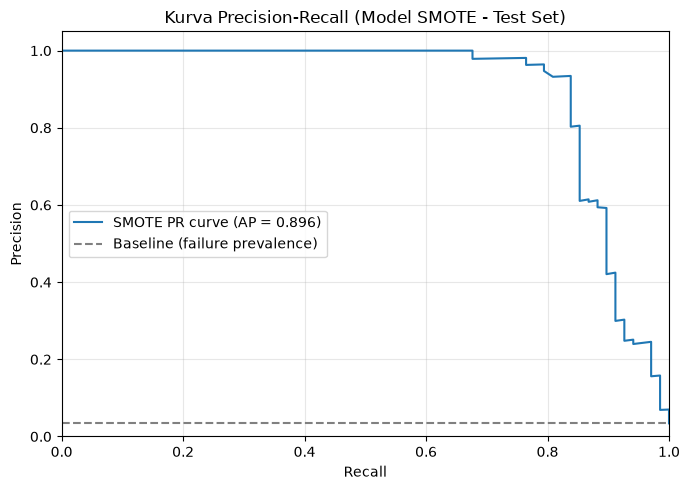

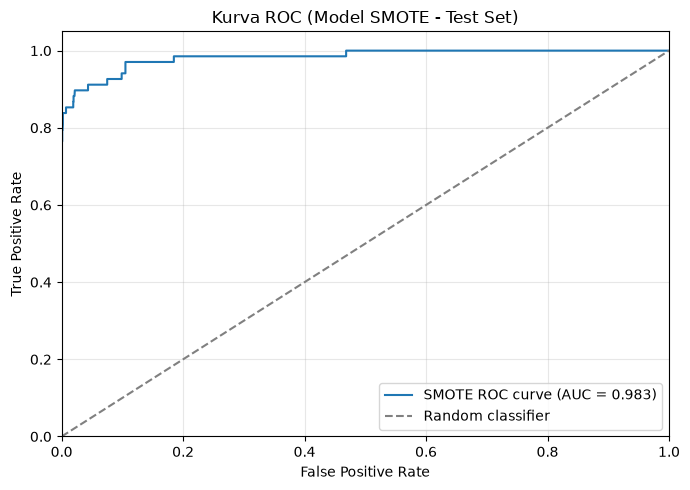

In [191]:
val_proba_smote = model_smote.predict_proba(X_val)[:, 1]
prec_s, rec_s, thr_s = precision_recall_curve(y_val, val_proba_smote)
f1_s = 2 * prec_s * rec_s / (prec_s + rec_s + 1e-9)
best_s = np.argmax(f1_s[:-1])
THRESHOLD_SMOTE = float(thr_s[best_s])
print(f"Best SMOTE threshold: {THRESHOLD_SMOTE:.3f}  (validation F1 = {f1_s[best_s]:.3f})")

test_proba_smote = model_smote.predict_proba(X_test)[:, 1]
test_pred_smote = (test_proba_smote >= THRESHOLD_SMOTE).astype(int)

print("\n--- SMOTE MODEL EVALUATION ON TEST SET ---")
print(classification_report(y_test, test_pred_smote, target_names=["Normal", "Failure"], digits=3))
print("PR-AUC :", round(average_precision_score(y_test, test_proba_smote), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba_smote), 4))

pr_precision_smote, pr_recall_smote, _ = precision_recall_curve(y_test, test_proba_smote)
pr_auc_smote = average_precision_score(y_test, test_proba_smote)
plt.figure(figsize=(7, 5))
plt.plot(pr_recall_smote, pr_precision_smote, label=f"SMOTE PR curve (AP = {pr_auc_smote:.3f})")
plt.axhline(y_test.mean(), linestyle="--", color="gray", label="Baseline (failure prevalence)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Kurva Precision-Recall (Model SMOTE - Test Set)")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fpr_smote, tpr_smote, _ = roc_curve(y_test, test_proba_smote)
roc_auc_smote = roc_auc_score(y_test, test_proba_smote)
plt.figure(figsize=(7, 5))
plt.plot(fpr_smote, tpr_smote, label=f"SMOTE ROC curve (AUC = {roc_auc_smote:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Kurva ROC (Model SMOTE - Test Set)")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Threshold Tuning

A threshold of 0.5 is rarely ideal for imbalanced data. We find the threshold with the best F1 score on the **validation set**, not the test set.

In [192]:
val_proba = model.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, val_proba)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = np.argmax(f1[:-1])
THRESHOLD = float(thr[best])
print(f"Best threshold: {THRESHOLD:.3f}  (validation F1 = {f1[best]:.3f})")

Best threshold: 0.814  (validation F1 = 0.868)


## 6. Evaluation on the Test Set

              precision    recall  f1-score   support

      Normal      0.993     0.995     0.994      1932
     Failure      0.844     0.794     0.818        68

    accuracy                          0.988      2000
   macro avg      0.918     0.894     0.906      2000
weighted avg      0.988     0.988     0.988      2000

PR-AUC : 0.8581
ROC-AUC: 0.9825


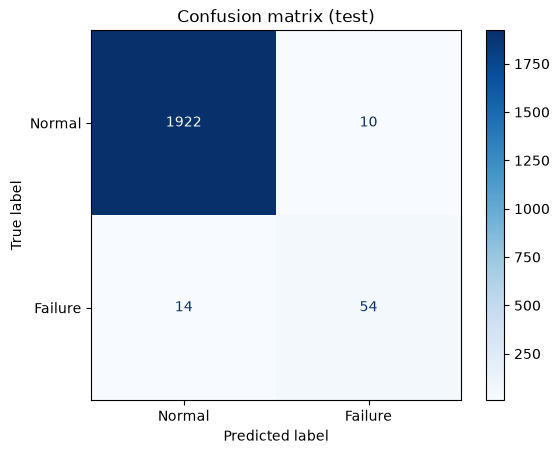

In [193]:
test_proba = model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)

print(classification_report(y_test, test_pred, target_names=["Normal", "Failure"], digits=3))
print("PR-AUC :", round(average_precision_score(y_test, test_proba), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 4))

ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred),
                       display_labels=["Normal", "Failure"]).plot(cmap="Blues")
plt.title("Confusion matrix (test)")
plt.show()

### 6.1 Overfitting Check: Train vs Test F1

Compare F1 on the **original training data** (not the SMOTE-resampled one) with F1 on the test set, using each model's own tuned threshold. A small gap means the model generalizes; a large gap signals overfitting.

In [194]:
from sklearn.metrics import f1_score

# use real data train (X_train, y_train), not SMOTE-resampled data (X_train_res, y_train_res)
for nama, m, thr in [("baseline", model, THRESHOLD),
                     ("smote", model_smote, THRESHOLD_SMOTE)]:
    f1_tr = f1_score(y_train, (m.predict_proba(X_train)[:, 1] >= thr).astype(int))
    f1_te = f1_score(y_test,  (m.predict_proba(X_test)[:, 1]  >= thr).astype(int))
    print(f"{nama:8s} | train F1 = {f1_tr:.3f} | test F1 = {f1_te:.3f} | difference = {f1_tr - f1_te:+.3f}")

baseline | train F1 = 0.893 | test F1 = 0.818 | difference = +0.075
smote    | train F1 = 0.871 | test F1 = 0.866 | difference = +0.005


## 7. Feature Importance

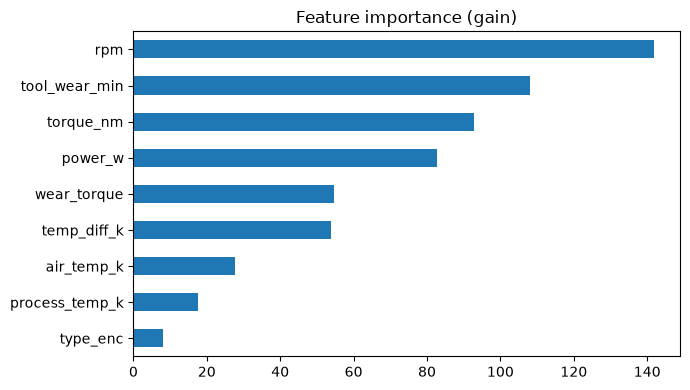

In [195]:
imp = pd.Series(model.get_booster().get_score(importance_type="gain"))
imp = imp.reindex(FEATURES).fillna(0).sort_values()
imp.plot(kind="barh", figsize=(7, 4), title="Feature importance (gain)")
plt.tight_layout()
plt.show()

## 8. Logging to MLflow

Both models (baseline and SMOTE) are logged as separate runs, including their parameters, validation and test metrics, plots, and the models themselves (with signatures). One model is selected as the **champion**, registered in the Model Registry, and assigned the `champion` alias. FastAPI loads the model through this alias, so no model file is hard-coded.

Automatic selection (`MODEL_TO_REGISTER=auto`) uses **F1 on the validation set**, not the test set, keeping the test set untouched. The threshold and feature list are stored as tags on the model version so the API uses exactly the same configuration as training.

The SMOTE run also logs the grid search results: best parameters, best CV PR-AUC, duration (`grid_seconds`), and the full CV table (`grid/cv_results.csv`).

In [196]:
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT)
client = MlflowClient()

LOG_PARAM_KEYS = ["n_estimators", "learning_rate", "max_depth", "subsample", "colsample_bytree",
                  "scale_pos_weight", "eval_metric", "early_stopping_rounds", "tree_method"]


def split_metrics(m, thr):
    """Precision/recall/F1 at the selected threshold + PR-AUC/ROC-AUC, for validation and test."""
    out = {}
    for split, (Xs, ys) in {"val": (X_val, y_val), "test": (X_test, y_test)}.items():
        proba = m.predict_proba(Xs)[:, 1]
        pred = (proba >= thr).astype(int)
        out[f"{split}_precision"] = precision_score(ys, pred, zero_division=0)
        out[f"{split}_recall"]    = recall_score(ys, pred, zero_division=0)
        out[f"{split}_f1"]        = f1_score(ys, pred, zero_division=0)
        out[f"{split}_pr_auc"]    = average_precision_score(ys, proba)
        out[f"{split}_roc_auc"]   = roc_auc_score(ys, proba)
    return {k: float(v) for k, v in out.items()}


def make_plots(m, thr):
    pred = (m.predict_proba(X_test)[:, 1] >= thr).astype(int)
    fig_cm, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Normal", "Failure"]).plot(cmap="Blues", ax=ax)
    ax.set_title("Confusion matrix (test)")
    fig_cm.tight_layout()

    fig_imp, ax2 = plt.subplots(figsize=(7, 4))
    imp = pd.Series(m.get_booster().get_score(importance_type="gain"))
    imp.reindex(FEATURES).fillna(0).sort_values().plot(kind="barh", ax=ax2,
                                                       title="Feature importance (gain)")
    fig_imp.tight_layout()
    return fig_cm, fig_imp


def log_variant(variant, m, thr, train_rows, train_failure_ratio,
                extra_params=None, extra_text=None):
    meta = {"variant": variant, "features": FEATURES, "type_map": TYPE_MAP, "threshold": thr}
    with mlflow.start_run(run_name=f"xgb_{variant}-{train_rows}") as run:
        mlflow.set_tags({"variant": variant, "data_source": DATA_SOURCE,
                         "git_sha": GIT_SHA, "framework": "xgboost"})
        params = {k: v for k, v in m.get_params().items() if k in LOG_PARAM_KEYS and v is not None}
        params.update(best_iteration=m.best_iteration, threshold=round(thr, 6),
                      train_rows=train_rows, train_failure_ratio=round(train_failure_ratio, 4),
                      n_features=len(FEATURES), random_state=RANDOM_STATE)
        if extra_params:
            params.update(extra_params)
        mlflow.log_params(params)
        for name, content in (extra_text or {}).items():
            mlflow.log_text(content, name)

        metrics = split_metrics(m, thr)
        mlflow.log_metrics(metrics)

        fig_cm, fig_imp = make_plots(m, thr)
        mlflow.log_figure(fig_cm, "plots/confusion_matrix.png")
        mlflow.log_figure(fig_imp, "plots/feature_importance.png")
        plt.close("all")
        mlflow.log_dict(meta, "meta/model_meta.json")

        sig_X = X_val.astype("float64")
        info = mlflow.xgboost.log_model(
            m, name="model",
            signature=infer_signature(sig_X, m.predict_proba(X_val)[:, 1]),
            input_example=sig_X.head(5))
    return {"variant": variant, "run_id": run.info.run_id, "model_uri": info.model_uri,
            "threshold": thr, "metrics": metrics}


results = {
    "baseline": log_variant("baseline", model, THRESHOLD,
                            len(y_train), float(y_train.mean())),
    "smote":    log_variant("smote", model_smote, THRESHOLD_SMOTE,
                            len(y_train_res), float(y_train_res.mean()),
                            extra_params={
                                "grid_best_cv_pr_auc": round(GRID_BEST_SCORE, 6),
                                "grid_seconds":        round(GRID_SECONDS, 2),
                                "grid_n_candidates":   N_CANDIDATES,
                                "grid_cv_folds":       GRID_CV_FOLDS,
                                "grid_best_params":    json.dumps(BEST_PARAMS),
                            },
                            extra_text={
                                "grid/param_grid.json": json.dumps(PARAM_GRID, indent=2),
                                "grid/cv_results.csv":  cv_df.assign(params=cv_df["params"].astype(str)).to_csv(index=False),
                            }),
}

summary = pd.DataFrame({k: v["metrics"] for k, v in results.items()}).T
summary[["val_f1", "val_pr_auc", "test_precision", "test_recall", "test_f1", "test_pr_auc"]].round(4)

🏃 View run xgb_baseline-6400 at: http://127.0.0.1:5000/#/experiments/1/runs/198194f3b6e94ed0b0678ab1932c381b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run xgb_smote-9274 at: http://127.0.0.1:5000/#/experiments/1/runs/290b8a5230284e778949491d3e488f72
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,val_f1,val_pr_auc,test_precision,test_recall,test_f1,test_pr_auc
baseline,0.8679,0.8813,0.8438,0.7941,0.8182,0.8581
smote,0.8846,0.9009,0.9322,0.8088,0.8661,0.8960


In [197]:
# Select the champion and register it in the Model Registry
if MODEL_TO_REGISTER == "auto":
    chosen = max(results, key=lambda k: results[k]["metrics"]["val_f1"])
else:
    chosen = MODEL_TO_REGISTER
best = results[chosen]
print(f"Champion: {chosen} (val_f1={best['metrics']['val_f1']:.3f}, "
      f"test_pr_auc={best['metrics']['test_pr_auc']:.3f}, threshold={best['threshold']:.3f})")

mv = mlflow.register_model(best["model_uri"], REGISTERED_MODEL_NAME)
tags = {
    "threshold": f"{best['threshold']:.6f}",
    "features": json.dumps(FEATURES),
    "type_map": json.dumps(TYPE_MAP),
    "variant": chosen,
    "run_id": best["run_id"],
    "git_sha": GIT_SHA,
    "val_f1": f"{best['metrics']['val_f1']:.4f}",
    "test_pr_auc": f"{best['metrics']['test_pr_auc']:.4f}",
}
for k, v in tags.items():
    client.set_model_version_tag(REGISTERED_MODEL_NAME, mv.version, k, v)
client.set_registered_model_alias(REGISTERED_MODEL_NAME, MODEL_ALIAS, mv.version)
print(f"Registered: models:/{REGISTERED_MODEL_NAME}@{MODEL_ALIAS} -> version {mv.version}")

Champion: smote (val_f1=0.885, test_pr_auc=0.896, threshold=0.813)


Registered model 'machine_failure_xgb' already exists. Creating a new version of this model...
2026/11/24 21:54:17 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: machine_failure_xgb, version 6
Created version '6' of model 'machine_failure_xgb'.


Registered: models:/machine_failure_xgb@champion -> version 6


## 9. Inference on One New Data Point (from the MLflow Registry)

The model is loaded from the registry through its alias, just as FastAPI does in production: not from a local file. The threshold and feature list are retrieved from the model version's tags.

According to the dataset rules, the data below is **expected to fail**: type L with `tool wear x torque` = 215 x 55 = 11,825, above the 11,000 threshold (overstrain). Temperature and power are still normal, so this tests whether the model detects the overstrain rule rather than merely guessing.

In [198]:
new_sample = {
    "type": "L",
    "air_temp_k": 300.5,
    "process_temp_k": 310.9,
    "rpm": 1500,
    "torque_nm": 55.0,
    "tool_wear_min": 215,
}

model_uri = f"models:/{REGISTERED_MODEL_NAME}@{MODEL_ALIAS}"
loaded = mlflow.xgboost.load_model(model_uri)
mv_loaded = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, MODEL_ALIAS)
feats = json.loads(mv_loaded.tags["features"])
thr = float(mv_loaded.tags["threshold"])

new_df = pd.DataFrame([new_sample])
new_X = make_features(new_df)[feats]

proba = float(loaded.predict_proba(new_X)[0, 1])
pred = int(proba >= thr)

print("Model               :", model_uri, f"(version {mv_loaded.version})")
print(new_X.T)
print(f"\nFailure probability: {proba:.3f}")
print(f"Threshold           : {thr:.3f}")
print("Prediction          :", "FAILURE" if pred else "NORMAL")
print("Rule-based expectation: FAILURE (overstrain, 11,825 > 11,000 for type L)")

Model               : models:/machine_failure_xgb@champion (version 6)
                           0
type_enc            0.000000
air_temp_k        300.500000
process_temp_k    310.900000
rpm              1500.000000
torque_nm          55.000000
tool_wear_min     215.000000
temp_diff_k        10.400000
power_w          8639.379797
wear_torque     11825.000000

Failure probability: 0.992
Threshold           : 0.813
Prediction          : FAILURE
Rule-based expectation: FAILURE (overstrain, 11,825 > 11,000 for type L)


## Notes for the Report

- The dataset is synthetic and its labels are generated by threshold rules, so a high score does not necessarily mean similar performance on real factory data. Mention this as a limitation.
- `RNF` (random failure, 0.1%) cannot be predicted from sensor readings, so a 100% recall is not realistic.
- For comparison, replace section 4 with Random Forest and Logistic Regression, then compare PR-AUC, recall, and F1 on the same test set.
- The `make_features` function is also used in `serving/app.py`. If you change the feature formulas in the notebook, update the API as well (the feature list and order automatically follow the model through MLflow tags, but the formulas do not).
- Grid search (18 combinations x 3 folds = 54 fits per cycle) runs on the training split only, with SMOTE inside an `imblearn` pipeline. Early stopping is not used inside the grid; it is used when the final model is trained.
- Inside the grid pipeline, SMOTE may produce fractional `type_enc` values. This is harmless for tree models; the final model uses the rounded values from section 3.1.
- Record `grid_seconds` per retraining cycle: it is useful for discussing training cost on the 1-core VPS.